<a href="https://colab.research.google.com/github/ppakseungh0/seungho.parctice/blob/main/tabm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip -q install kagglehub tabm scikit-learn pandas numpy scipy matplotlib

In [ ]:
import os
from pathlib import Path
import kagglehub

kagglehub.login()

DATA_DIR = Path(kagglehub.competition_download("playground-series-s6e11"))
print("Data directory:", DATA_DIR)
print("Files:", [p.name for p in DATA_DIR.iterdir()])

100%|██████████| 29.5M/29.5M [00:02<00:00, 13.6MB/s]

Extracting files...


Data directory: /root/.cache/kagglehub/competitions/playground-series-s6e11
Files: ['test.csv', 'sample_submission.csv', 'train.csv']
Kaggle credentials set.
Kaggle credentials successfully validated.


KGAT_222b912cba1a2a60bcb2b2b2415a59ed

In [ ]:
import numpy as np
import pandas as pd

train_path = next(DATA_DIR.rglob("train.csv"))
test_path = next(DATA_DIR.rglob("test.csv"))

train = pd.read_csv(train_path)
test = pd.read_csv(test_path)

TARGET = "is_fraud"
ID_COL = "id"

assert TARGET in train.columns, f"Target '{TARGET}' not found"
assert ID_COL in train.columns and ID_COL in test.columns, "id column not found"
assert TARGET not in test.columns

print("Train shape:", train.shape)
print("Test shape:", test.shape)
print("Target rate:", train[TARGET].mean())
display(train.head())
display(train.dtypes.value_counts())

Train shape: (699960, 26)
Test shape: (299984, 25)
Target rate: 0.016699525687182123


,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,...,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,is_fraud
0,0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,...,OTP,POS,iPhone,False,False,False,False,False,False,0.0
1,1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,...,PIN,In-App,Android Phone,False,False,False,False,False,False,0.0
2,2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,...,OTP,Online,Tablet,False,False,True,False,False,False,0.0
3,3,37.44,5.13,4,8.67,48,48,2217.67,0,20.7,...,3D Secure,POS,Android Phone,False,False,False,False,False,False,0.0
4,4,653.85,0.80,4,11.69,37,52,3291.06,0,34.8,...,3D Secure,Online,Windows PC,False,False,False,False,False,False,0.0


,count
int64,8
float64,7
bool,6
object,5


In [ ]:
from sklearn.model_selection import StratifiedKFold
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

FEATURES = [c for c in train.columns if c not in [TARGET, ID_COL]]

# dtype을 기준으로 수치형/범주형 변수를 자동 구분
NUM_COLS = [
    c for c in FEATURES
    if pd.api.types.is_numeric_dtype(train[c])
]
CAT_COLS = [c for c in FEATURES if c not in NUM_COLS]

print("Number of features:", len(FEATURES))
print("Numeric:", len(NUM_COLS), NUM_COLS)
print("Categorical:", len(CAT_COLS), CAT_COLS)

# 학습/테스트 양쪽에 존재하는 열만 사용하고 순서를 고정
assert set(FEATURES).issubset(test.columns)

Number of features: 24
Numeric: 19 ['amount_usd', 'hours_since_last_txn', 'txn_count_last_24h', 'distance_from_home_km', 'card_age_months', 'customer_age', 'account_balance_usd', 'cvv_retry_count', 'velocity_score', 'time_of_day_hour', 'day_of_week', 'merchant_risk_score', 'prior_disputes', 'is_foreign_transaction', 'is_new_merchant', 'used_vpn', 'ip_country_mismatch', 'billing_shipping_mismatch', 'is_ai_generated_scam_attempt']
Categorical: 5 ['merchant_category', 'card_type', 'auth_method', 'channel', 'device_type']


In [ ]:
import random
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from tabm import TabM
from sklearn.metrics import roc_auc_score

SEED = 42
N_SPLITS = 5
EPOCHS = 30
BATCH_SIZE = 4096
PATIENCE = 5
LEARNING_RATE = 2e-3
WEIGHT_DECAY = 3e-4

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

seed_everything(SEED)

def prepare_fold_data(X_train_df, X_valid_df, X_test_df):
    # 수치형: 학습 fold의 중앙값으로 결측치 대체 후 표준화
    if NUM_COLS:
        num_imputer = SimpleImputer(strategy="median")
        num_scaler = StandardScaler()

        xtr_num = num_imputer.fit_transform(X_train_df[NUM_COLS])
        xva_num = num_imputer.transform(X_valid_df[NUM_COLS])
        xte_num = num_imputer.transform(X_test_df[NUM_COLS])

        xtr_num = num_scaler.fit_transform(xtr_num)
        xva_num = num_scaler.transform(xva_num)
        xte_num = num_scaler.transform(xte_num)
    else:
        xtr_num = np.zeros((len(X_train_df), 0), dtype=np.float32)
        xva_num = np.zeros((len(X_valid_df), 0), dtype=np.float32)
        xte_num = np.zeros((len(X_test_df), 0), dtype=np.float32)

    # 범주형: 학습 fold에서만 범주 사전을 만든다
    # 0은 결측/미지 범주, 알려진 범주는 1부터 시작한다
    cat_maps = {}
    cat_cardinalities = []

    def encode_cat(series, mapping):
        values = series.astype("string").fillna("__MISSING__")
        return values.map(mapping).fillna(0).astype("int64").to_numpy()

    xtr_cat_list, xva_cat_list, xte_cat_list = [], [], []

    for col in CAT_COLS:
        values = X_train_df[col].astype("string").fillna("__MISSING__")
        categories = pd.Index(values.unique())
        mapping = {value: i + 1 for i, value in enumerate(categories)}
        cat_maps[col] = mapping

        xtr_cat_list.append(encode_cat(X_train_df[col], mapping))
        xva_cat_list.append(encode_cat(X_valid_df[col], mapping))
        xte_cat_list.append(encode_cat(X_test_df[col], mapping))

        # 0번 미지 범주 포함
        cat_cardinalities.append(len(mapping) + 1)

    if CAT_COLS:
        xtr_cat = np.column_stack(xtr_cat_list)
        xva_cat = np.column_stack(xva_cat_list)
        xte_cat = np.column_stack(xte_cat_list)
    else:
        xtr_cat = np.zeros((len(X_train_df), 0), dtype=np.int64)
        xva_cat = np.zeros((len(X_valid_df), 0), dtype=np.int64)
        xte_cat = np.zeros((len(X_test_df), 0), dtype=np.int64)

    return (
        xtr_num.astype("float32"), xva_num.astype("float32"), xte_num.astype("float32"),
        xtr_cat.astype("int64"), xva_cat.astype("int64"), xte_cat.astype("int64"),
        cat_cardinalities
    )

def make_model(n_num_features, cat_cardinalities):
    model = TabM.make(
        n_num_features=n_num_features,
        cat_cardinalities=cat_cardinalities if cat_cardinalities else None,
        d_out=1,
        k=16,
        n_blocks=2,
        d_block=256,
        dropout=0.1
    )
    return model.to(DEVICE)

def predict_tabm(model, x_num, x_cat):
    model.eval()
    with torch.no_grad():
        num_tensor = torch.tensor(x_num, dtype=torch.float32, device=DEVICE)
        cat_tensor = torch.tensor(x_cat, dtype=torch.long, device=DEVICE)

        outputs = []
        for start in range(0, len(num_tensor), BATCH_SIZE):
            end = start + BATCH_SIZE
            if x_cat.shape[1] > 0:
                logits = model(num_tensor[start:end], cat_tensor[start:end])
            else:
                logits = model(num_tensor[start:end])
            # logits shape: (batch, k, 1)
            probs = torch.sigmoid(logits).mean(dim=1).squeeze(-1)
            outputs.append(probs.cpu().numpy())

    return np.concatenate(outputs)

def train_one_fold(Xtr_num, Xva_num, Xtr_cat, Xva_cat, ytr, yva, cat_cardinalities, fold):
    model = make_model(Xtr_num.shape[1], cat_cardinalities)
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY
    )
    criterion = nn.BCEWithLogitsLoss()

    train_ds = TensorDataset(
        torch.tensor(Xtr_num, dtype=torch.float32),
        torch.tensor(Xtr_cat, dtype=torch.long),
        torch.tensor(ytr, dtype=torch.float32)
    )
    train_loader = DataLoader(
        train_ds,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=0,
        pin_memory=(DEVICE.type == "cuda")
    )

    xva_num_t = torch.tensor(Xva_num, dtype=torch.float32, device=DEVICE)
    xva_cat_t = torch.tensor(Xva_cat, dtype=torch.long, device=DEVICE)
    yva_t = torch.tensor(yva, dtype=torch.float32, device=DEVICE)

    best_auc = -np.inf
    best_state = None
    best_epoch = 0
    wait = 0

    for epoch in range(1, EPOCHS + 1):
        model.train()
        running_loss = 0.0

        for xb_num, xb_cat, yb in train_loader:
            xb_num = xb_num.to(DEVICE, non_blocking=True)
            xb_cat = xb_cat.to(DEVICE, non_blocking=True)
            yb = yb.to(DEVICE, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)

            if xb_cat.shape[1] > 0:
                logits = model(xb_num, xb_cat)
            else:
                logits = model(xb_num)

            # 각 TabM 멤버의 예측을 개별적으로 학습
            y_expanded = yb.view(-1, 1, 1).expand_as(logits)
            loss = criterion(logits, y_expanded)

            loss.backward()
            optimizer.step()
            running_loss += loss.item()

        model.eval()
        with torch.no_grad():
            if xva_cat_t.shape[1] > 0:
                val_logits = model(xva_num_t, xva_cat_t)
            else:
                val_logits = model(xva_num_t)

            val_prob = torch.sigmoid(val_logits).mean(dim=1).squeeze(-1)
            val_auc = roc_auc_score(yva, val_prob.cpu().numpy())

        mean_loss = running_loss / max(1, len(train_loader))
        print(
            f"Fold {fold} | Epoch {epoch:02d} | "
            f"Loss {mean_loss:.5f} | Valid AUC {val_auc:.6f}"
        )

        if val_auc > best_auc:
            best_auc = val_auc
            best_epoch = epoch
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            wait = 0
        else:
            wait += 1
            if wait >= PATIENCE:
                print(f"Early stopping at epoch {epoch}")
                break

    model.load_state_dict(best_state)
    return model, best_auc, best_epoch

Device: cpu


In [ ]:
X = train[FEATURES].copy()
X_test = test[FEATURES].copy()
y = train[TARGET].astype("int8").to_numpy()

oof_pred = np.zeros(len(train), dtype=np.float32)
test_pred = np.zeros(len(test), dtype=np.float32)

fold_rows = []
skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)

for fold, (tr_idx, va_idx) in enumerate(skf.split(X, y), 1):
    print("\n" + "=" * 60)
    print(f"FOLD {fold}/{N_SPLITS}")
    print("=" * 60)

    Xtr_df = X.iloc[tr_idx].copy()
    Xva_df = X.iloc[va_idx].copy()

    (
        Xtr_num, Xva_num, Xte_num,
        Xtr_cat, Xva_cat, Xte_cat,
        cat_cardinalities
    ) = prepare_fold_data(Xtr_df, Xva_df, X_test)

    model, best_auc, best_epoch = train_one_fold(
        Xtr_num, Xva_num,
        Xtr_cat, Xva_cat,
        y[tr_idx], y[va_idx],
        cat_cardinalities,
        fold
    )

    oof_pred[va_idx] = predict_tabm(model, Xva_num, Xva_cat)
    test_pred += predict_tabm(model, Xte_num, Xte_cat) / N_SPLITS

    fold_rows.append({
        "fold": fold,
        "valid_auc": best_auc,
        "best_epoch": best_epoch
    })

    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

fold_results = pd.DataFrame(fold_rows)
display(fold_results)

overall_auc = roc_auc_score(y, oof_pred)
print(f"Overall OOF AUC: {overall_auc:.8f}")
print(f"Fold AUC mean:   {fold_results['valid_auc'].mean():.8f}")
print(f"Fold AUC std:    {fold_results['valid_auc'].std():.8f}")


FOLD 1/5
Fold 1 | Epoch 01 | Loss 0.10176 | Valid AUC 0.940483
Fold 1 | Epoch 02 | Loss 0.04899 | Valid AUC 0.941790
Fold 1 | Epoch 03 | Loss 0.04808 | Valid AUC 0.941925
Fold 1 | Epoch 04 | Loss 0.04764 | Valid AUC 0.942113
Fold 1 | Epoch 05 | Loss 0.04753 | Valid AUC 0.942349
Fold 1 | Epoch 06 | Loss 0.04735 | Valid AUC 0.941902
Fold 1 | Epoch 07 | Loss 0.04726 | Valid AUC 0.942117
Fold 1 | Epoch 08 | Loss 0.04719 | Valid AUC 0.942094
Fold 1 | Epoch 09 | Loss 0.04712 | Valid AUC 0.942253
Fold 1 | Epoch 10 | Loss 0.04693 | Valid AUC 0.942111
Early stopping at epoch 10

FOLD 2/5
Fold 2 | Epoch 01 | Loss 0.10035 | Valid AUC 0.942036
Fold 2 | Epoch 02 | Loss 0.04915 | Valid AUC 0.944149
Fold 2 | Epoch 03 | Loss 0.04826 | Valid AUC 0.944572
Fold 2 | Epoch 04 | Loss 0.04790 | Valid AUC 0.944224
Fold 2 | Epoch 05 | Loss 0.04775 | Valid AUC 0.944219
Fold 2 | Epoch 06 | Loss 0.04753 | Valid AUC 0.944290
Fold 2 | Epoch 07 | Loss 0.04743 | Valid AUC 0.944602
Fold 2 | Epoch 08 | Loss 0.04734 | 

,fold,valid_auc,best_epoch
0,1,0.942349,5
1,2,0.944848,9
2,3,0.948230,14
3,4,0.943297,13
4,5,0.938702,21


Overall OOF AUC: 0.94293419
Fold AUC mean:   0.94348535
Fold AUC std:    0.00348476


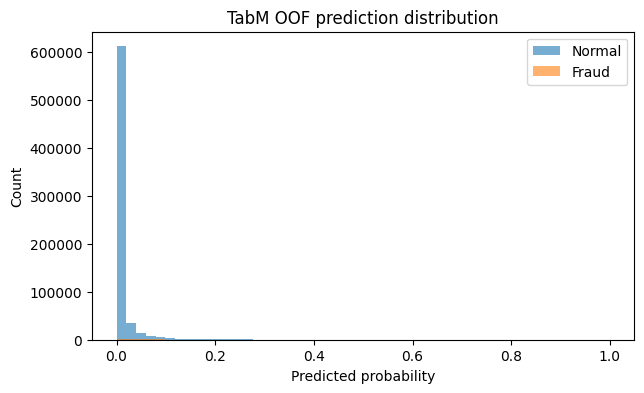

Saved:
/content/tabm_oof.csv
/content/tabm_test_predictions.csv
/content/tabm_fold_results.csv


In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4))
plt.hist(oof_pred[y == 0], bins=50, alpha=0.6, label="Normal")
plt.hist(oof_pred[y == 1], bins=50, alpha=0.6, label="Fraud")
plt.xlabel("Predicted probability")
plt.ylabel("Count")
plt.title("TabM OOF prediction distribution")
plt.legend()
plt.show()

oof_df = pd.DataFrame({
    ID_COL: train[ID_COL].to_numpy(),
    TARGET: y,
    "tabm_oof": oof_pred
})
test_pred_df = pd.DataFrame({
    ID_COL: test[ID_COL].to_numpy(),
    TARGET: test_pred
})

oof_df.to_csv("/content/tabm_oof.csv", index=False)
test_pred_df.to_csv("/content/tabm_test_predictions.csv", index=False)
fold_results.to_csv("/content/tabm_fold_results.csv", index=False)

print("Saved:")
print("/content/tabm_oof.csv")
print("/content/tabm_test_predictions.csv")
print("/content/tabm_fold_results.csv")

In [ ]:
from google.colab import drive

drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [ ]:
import os

save_dir = "/content/drive/MyDrive/S6E11_TabM"

os.makedirs(save_dir, exist_ok=True)

print("Drive connected:", os.path.exists("/content/drive/MyDrive"))

Drive connected: True


In [ ]:
import shutil
import os

save_dir = "/content/drive/MyDrive/S6E11_TabM"

files = [
    "/content/tabm_oof.csv",
    "/content/tabm_test_predictions.csv",
    "/content/tabm_fold_results.csv"
]

for file_path in files:
    assert os.path.exists(file_path), f"Missing: {file_path}"
    shutil.copy2(file_path, save_dir)

print("Backup completed!")

for f in os.listdir(save_dir):
    print(f, os.path.getsize(os.path.join(save_dir, f)), "bytes")

Backup completed!
tabm_oof.csv 15143590 bytes
tabm_test_predictions.csv 5936590 bytes
tabm_fold_results.csv 142 bytes
